# Etapa 4 — Modelo Dimensional Lógico

**Reto de Business Intelligence — Socio formador OTC Consulting**  
**José Fernando Munguía Zertuche — A01199357**

Este cuaderno valida y genera el modelo dimensional que se documenta en `docs/ETAPA_4.md`. Hace cuatro cosas sobre las tablas acondicionadas de la Etapa 3:

1. Comprueba el grano declarado y la integridad referencial de las llaves.
2. Calcula las métricas y su cobertura real.
3. Construye la tabla de hechos con sus llaves sustitutas y revisa las cardinalidades de las dimensiones.
4. Genera el diagrama del modelo y la matriz de bus en `docs/`.

El diseño sigue los cuatro pasos de Kimball: proceso de negocio, granularidad, dimensiones y hechos.

In [1]:
from pathlib import Path

import pandas as pd

RUTA = Path('../data/acondicionado')
DOCS = Path('../docs')
CORTE = pd.Timestamp('2026-11-20')

FUENTES = [
    'colaborador_acondicionado', 'asignacion_acondicionada', 'proyecto_acondicionado',
    'cliente_acondicionado', 'activo_acondicionado', 'habilidad_acondicionada',
    'matriz_habilidad_long', 'departamento_acondicionado', 'kpi_habilidad',
]
datos = {nombre: pd.read_csv(RUTA / f'{nombre}.csv') for nombre in FUENTES}

for nombre, df in datos.items():
    print(f'{nombre:28s} {len(df):>5,d} filas x {len(df.columns):>2d} columnas')

colaborador_acondicionado      107 filas x 62 columnas
asignacion_acondicionada        31 filas x 29 columnas
proyecto_acondicionado          12 filas x 19 columnas
cliente_acondicionado            8 filas x 19 columnas
activo_acondicionado           123 filas x 25 columnas
habilidad_acondicionada         71 filas x  8 columnas
matriz_habilidad_long        1,539 filas x  4 columnas
departamento_acondicionado       6 filas x  8 columnas
kpi_habilidad                   69 filas x  3 columnas


## A.2 y A.3 — Objeto de estudio y granularidad

El objeto de estudio es la asignación de consultores a proyectos de clientes y su costo. El grano que se declara es **una fila por asignación**, con el colaborador, el proyecto, el rol y el periodo. Antes de aceptarlo se comprueba contra los datos: que la llave natural sea única, que no haya duplicados lógicos y que ninguna llave foránea apunte a un registro inexistente.

In [2]:
a = datos['asignacion_acondicionada']
c = datos['colaborador_acondicionado']

print('Grano declarado: una fila por asignación de colaborador a proyecto')
print(f'  filas ......................................... {len(a)}')
print(f'  id_asignacion único ........................... {a.id_asignacion.is_unique}')
print(f'  duplicados (colaborador, proyecto, inicio) .... {int(a.duplicated(["id_colaborador", "id_proyecto", "inicio"]).sum())}')
print(f'  colaboradores distintos ....................... {a.id_colaborador.nunique()}')
print(f'  proyectos / clientes .......................... {a.id_proyecto.nunique()} / {a.id_cliente.nunique()}')
print(f'  máximo de asignaciones por colaborador ........ {int(a.id_colaborador.value_counts().max())}')
print(f'  valores de pct_dedicacion ..................... {sorted(a.pct_dedicacion.unique())}')
print(f'  asignaciones sin rol capturado ................ {int(a.rol_asignado.isna().sum())}')

referencias = {
    'id_colaborador': set(c.id_colaborador),
    'id_proyecto': set(datos['proyecto_acondicionado'].id_proyecto),
    'id_cliente': set(datos['cliente_acondicionado'].id_cliente),
}
for columna, universo in referencias.items():
    print(f'  huérfanos en {columna:15s} ................... {int((~a[columna].isin(universo)).sum())}')

m = datos['matriz_habilidad_long']
print(f'  matriz sin id de colaborador .................. {int(m.id_colaborador.isna().sum())} filas')
print(f'  matriz con id inexistente ..................... {int((~m.id_colaborador.dropna().isin(referencias["id_colaborador"])).sum())} filas')

catalogo_areas = {nombre.casefold() for nombre in datos['departamento_acondicionado'].nombre}
areas = sorted({area for area in c.departamento.dropna() if area.casefold() not in catalogo_areas})
print(f'  áreas sin coincidencia en el catálogo ......... {areas if areas else "ninguna"}')

Grano declarado: una fila por asignación de colaborador a proyecto
  filas ......................................... 31
  id_asignacion único ........................... True
  duplicados (colaborador, proyecto, inicio) .... 0
  colaboradores distintos ....................... 30
  proyectos / clientes .......................... 4 / 3
  máximo de asignaciones por colaborador ........ 2
  valores de pct_dedicacion ..................... [np.float64(100.0)]
  asignaciones sin rol capturado ................ 29
  huérfanos en id_colaborador  ................... 0
  huérfanos en id_proyecto     ................... 0
  huérfanos en id_cliente      ................... 0
  matriz sin id de colaborador .................. 10 filas
  matriz con id inexistente ..................... 0 filas
  áreas sin coincidencia en el catálogo ......... ninguna


El grano se sostiene: 31 asignaciones únicas, sin duplicados lógicos y sin huérfanos. Las 31 filas cubren a 30 personas, 3 clientes y 4 proyectos, y una persona tiene dos asignaciones.

También quedan a la vista los tres huecos que el modelo debe representar y no esconder: 29 asignaciones sin rol, 21 sin fecha de inicio real (la fuente traía el centinela 1990-01-01) y 10 filas de la matriz sin colaborador. En el modelo, esos casos se cargan con la llave 0 de su dimensión; no se eliminan.

## A.4 — Métricas y su cobertura

Las medidas del hecho se calculan con las reglas del acondicionamiento: el costo se prorratea por la dedicación registrada y los días se cuentan desde la fecha de inicio real, nunca desde el centinela.

In [3]:
personas = datos['colaborador_acondicionado'].set_index('id_colaborador')

a = datos['asignacion_acondicionada'].copy()
a['costo_mensual'] = a.id_colaborador.map(personas['costo_mensual'])
a['costo_hora'] = a.id_colaborador.map(personas['costo_hora'])
a['costo_mensual_asignado'] = a.costo_mensual * a.pct_dedicacion / 100
a['costo_hora_asignado'] = a.costo_hora * a.pct_dedicacion / 100

inicio = pd.to_datetime(a.fecha_inicio, errors='coerce')
fin = pd.to_datetime(a.fecha_fin, errors='coerce')
a['dias_asignados'] = (fin.fillna(CORTE) - inicio).dt.days

print(f'Costo mensual asignado ....... ${a.costo_mensual_asignado.sum():,.2f}')
print(f'Asignaciones con costo ....... {int(a.costo_mensual_asignado.notna().sum())} de {len(a)}')
print(f'Días asignados calculables ... {int(a.dias_asignados.notna().sum())} de {len(a)}')
print(f'Días para el fin ............. {sorted(a.dias_para_fin.dropna().astype(int).tolist())}')
print(f'Ingreso facturable ........... 0 de {len(a)} (tarifas y horas no capturadas)')

activos = datos['activo_acondicionado']
print(f'Costo de activos conocido .... ${activos.costo.sum():,.2f} en {int(activos.costo.notna().sum())} de {len(activos)} activos')
print(f'Equipos por recuperar ........ {int(activos.pendiente_recuperar.sum())} por ${activos.loc[activos.pendiente_recuperar == 1, "costo"].sum():,.2f}')

Costo mensual asignado ....... $2,025,644.02
Asignaciones con costo ....... 31 de 31
Días asignados calculables ... 10 de 31
Días para el fin ............. [42, 42, 42, 223, 223, 223, 589]
Ingreso facturable ........... 0 de 31 (tarifas y horas no capturadas)
Costo de activos conocido .... $567,915.55 en 53 de 123 activos
Equipos por recuperar ........ 9 por $40,693.00


## A.5 — Cardinalidades de las dimensiones

Cada dimensión tiene su llave natural y una fila extra para el miembro desconocido (llave 0). El conteo se toma de los datos, no se supone.

In [4]:
dimensiones = pd.DataFrame([
    ('dim_tiempo', 9497, 'sk_tiempo (AAAAMMDD)'),
    ('dim_colaborador', c.id_colaborador.nunique(), 'id_colaborador'),
    ('dim_puesto', c.id_puesto.nunique(), 'id_puesto'),
    ('dim_departamento', datos['departamento_acondicionado'].codigo.nunique(), 'codigo'),
    ('dim_cliente', datos['cliente_acondicionado'].id_cliente.nunique(), 'id_cliente'),
    ('dim_proyecto', datos['proyecto_acondicionado'].id_proyecto.nunique(), 'id_proyecto'),
    ('dim_rol', a.rol_asignado.nunique(), 'rol_asignado'),
    ('dim_habilidad', datos['habilidad_acondicionada'].cod_habilidad.nunique(), 'cod_habilidad'),
    ('dim_activo', datos['activo_acondicionado'].codigo.nunique(), 'codigo'),
], columns=['dimensión', 'filas naturales', 'llave natural'])

dimensiones['con miembro desconocido'] = dimensiones['filas naturales'] + 1
dimensiones

,dimensión,filas naturales,llave natural,con miembro desconocido
0,dim_tiempo,9497,sk_tiempo (AAAAMMDD),9498
1,dim_colaborador,107,id_colaborador,108
2,dim_puesto,23,id_puesto,24
3,dim_departamento,6,codigo,7
4,dim_cliente,8,id_cliente,9
5,dim_proyecto,12,id_proyecto,13
6,dim_rol,1,rol_asignado,2
7,dim_habilidad,71,cod_habilidad,72
8,dim_activo,123,codigo,124


## A.6 y B.3 — Diagrama del modelo y matriz de bus

El siguiente bloque define el dibujo y lo guarda en `docs/`. No se dibuja a mano: la posición de cada caja, sus atributos y las flechas salen de las definiciones del modelo.

In [5]:
"""Dibujo del modelo dimensional logico del reto OTC (Etapa 4).

Genera dos imagenes:
  - modelo_dimensional_logico.png : estrella del hecho asignacion
  - matriz_bus.png                : matriz de bus de los tres hechos
"""
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle

NAVY = "#12294a"
AZUL = "#2e5f8a"
GRIS = "#8a94a6"
TINTA = "#1f2937"
SUAVE = "#6b7280"
AMBAR = "#b45309"
FONDO = "#ffffff"


def _caja(ax, cx, cy, w, titulo, subtitulo, filas, color, cols=1, fs=5.9):
    """Dibuja una caja con encabezado y filas (texto, etiqueta, tipo)."""
    por_col = math.ceil(len(filas) / cols)
    alto = 0.40 + (0.22 if subtitulo else 0.0) + por_col * 0.185 + 0.14
    arriba = cy + alto / 2

    ax.add_patch(FancyBboxPatch(
        (cx - w / 2, cy - alto / 2), w, alto,
        boxstyle="round,pad=0,rounding_size=0.10",
        facecolor=FONDO, edgecolor=color, linewidth=1.3, zorder=3))
    ax.add_patch(FancyBboxPatch(
        (cx - w / 2, arriba - 0.40), w, 0.40,
        boxstyle="round,pad=0,rounding_size=0.10",
        facecolor=color, edgecolor=color, linewidth=0, zorder=4))
    ax.add_patch(Rectangle(
        (cx - w / 2, arriba - 0.40), w, 0.12,
        facecolor=color, edgecolor="none", zorder=4))
    ax.text(cx, arriba - 0.20, titulo, ha="center", va="center",
            color="white", fontsize=8.0, fontweight="bold", zorder=5)

    if subtitulo:
        ax.text(cx, arriba - 0.51, subtitulo, ha="center", va="center",
                color=SUAVE, fontsize=5.4, style="italic", zorder=5)
        y0 = arriba - 0.74
    else:
        y0 = arriba - 0.52

    ancho_col = (w - 0.24) / cols
    for i, (texto, etiqueta, tipo) in enumerate(filas):
        col = i // por_col
        fila = i % por_col
        x = cx - w / 2 + 0.14 + col * ancho_col
        y = y0 - fila * 0.185

        if tipo == "k":
            estilo = dict(color=NAVY, fontweight="bold", fontsize=fs)
        elif tipo == "m":
            estilo = dict(color=TINTA, fontsize=fs)
        elif tipo == "n":
            estilo = dict(color="#9aa3b2", fontsize=fs, style="italic")
        else:
            estilo = dict(color="#374151", fontsize=fs)
        ax.text(x, y, texto, ha="left", va="center", zorder=5, **estilo)

        if etiqueta:
            color_tag = AMBAR if tipo == "m" else (NAVY if tipo == "k" else SUAVE)
            ax.text(x + ancho_col - 0.10, y, etiqueta, ha="right", va="center",
                    color=color_tag, fontsize=4.9, zorder=5,
                    fontweight="bold" if tipo in ("k", "m") else "normal")

    return dict(izq=(cx - w / 2, cy), der=(cx + w / 2, cy),
                arriba=(cx, cy + alto / 2), abajo=(cx, cy - alto / 2))


def _flecha(ax, origen, destino):
    ax.add_patch(FancyArrowPatch(
        origen, destino, arrowstyle="-|>", mutation_scale=9,
        color=GRIS, linewidth=1.1, zorder=6, shrinkA=1, shrinkB=3))


def dibujar_estrella(destino):
    fig, ax = plt.subplots(figsize=(26, 15), dpi=150)
    fig.patch.set_facecolor(FONDO)
    ax.set_facecolor(FONDO)
    ax.set_xlim(0, 26)
    ax.set_ylim(0, 15)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.text(13, 14.62, "Modelo Dimensional Lógico — Hecho Asignación",
            ha="center", va="center", fontsize=16, fontweight="bold", color=NAVY)
    ax.text(13, 14.18,
            "Grano: una fila por asignación de un colaborador a un proyecto, con su rol y su periodo  ·  "
            "31 asignaciones  ·  corte 2026-11-20",
            ha="center", va="center", fontsize=8.6, color=SUAVE)

    fact = [
        ("sk_asignacion", "PK", "k"),
        ("id_asignacion", "DD", "k"),
        ("sk_tiempo_inicio", "FK", "k"),
        ("sk_tiempo_fin", "FK", "k"),
        ("sk_colaborador", "FK", "k"),
        ("sk_puesto", "FK", "k"),
        ("sk_departamento", "FK", "k"),
        ("sk_cliente", "FK", "k"),
        ("sk_proyecto", "FK", "k"),
        ("sk_rol", "FK", "k"),
        ("tipo_de_asignacion", "DD", "k"),
        ("pct_dedicacion", "%", "m"),
        ("costo_mensual_asignado", "MXN", "m"),
        ("costo_hora_asignado", "MXN/h", "m"),
        ("días_asignados", "días", "m"),
        ("días_para_fin", "días", "m"),
        ("es_vigente", "0/1", "m"),
        ("ingreso_facturable", "n/d", "n"),
        ("margen", "n/d", "n"),
    ]

    dims = [
        # cx, cy, w, titulo, subtitulo, filas
        (4.05, 12.05, 6.5, "DIM TIEMPO", "9,497 días · SCD0", [
            ("sk_tiempo", "PK", "k"), ("fecha", "fecha", "a"), ("año", "int", "a"),
            ("trimestre", "int", "a"), ("mes", "int", "a"), ("nombre_mes", "texto", "a"),
            ("semana_iso", "int", "a"), ("día_semana", "texto", "a"),
            ("es_fin_semana", "0/1", "a"), ("año_mes", "texto", "a")]),
        (4.05, 7.55, 6.5, "DIM COLABORADOR", "107 + desconocido · SCD2", [
            ("sk_colaborador", "PK", "k"), ("id_colaborador", "NK", "k"),
            ("nombre_completo", "texto", "a"), ("genero", "texto", "a"),
            ("ciudad", "texto", "a"), ("estatus", "texto", "a"),
            ("puesto", "texto", "a"), ("departamento", "texto", "a"),
            ("fecha_incorporación", "fecha", "a"), ("fecha_baja", "fecha", "a"),
            ("fecha_nacimiento", "fecha", "a"), ("tipo_nomina", "texto", "a"),
            ("sueldo_neto_total", "MXN", "a"), ("sueldo_total_integrado", "MXN", "a"),
            ("costo_mensual", "MXN", "a"), ("costo_hora", "MXN/h", "a"),
            ("es_plantilla", "0/1", "a"), ("antiguedad_meses", "meses", "a"),
            ("edad", "años", "a"), ("baja_primer_anio", "0/1", "a"),
            ("tiene_asignacion_vigente", "0/1", "a"), ("dedicacion_total_pct", "%", "a"),
            ("sobreasignado", "0/1", "a"), ("dias_en_banca", "días", "a"),
            ("pct_expediente", "%", "a"), ("expediente_completo", "0/1", "a"),
            ("tiene_contrato", "0/1", "a"), ("inversion_equipo_col", "MXN", "a"),
            ("banderas falta_*", "7", "a"), ("version_scd", "int", "a"),
            ("vigente_desde", "fecha", "a"), ("vigente_hasta", "fecha", "a"),
            ("es_actual", "0/1", "a")]),
        (4.05, 3.02, 6.5, "DIM PUESTO", "23 + desconocido · SCD1", [
            ("sk_puesto", "PK", "k"), ("id_puesto", "NK", "k"),
            ("puesto", "texto", "a")]),
        (21.95, 12.05, 6.5, "DIM CLIENTE", "8 + desconocido · SCD1", [
            ("sk_cliente", "PK", "k"), ("id_cliente", "NK", "k"),
            ("codigo_cliente", "texto", "a"), ("cliente", "texto", "a"),
            ("industria", "texto", "a"), ("ciudad", "texto", "a"),
            ("estado", "texto", "a"), ("pais", "texto", "a"),
            ("contacto_nom", "texto", "a"), ("estatus", "texto", "a"),
            ("n_proyectos", "int", "a")]),
        (21.95, 7.55, 6.5, "DIM PROYECTO", "12 + desconocido · SCD2", [
            ("sk_proyecto", "PK", "k"), ("id_proyecto", "NK", "k"),
            ("llave_proyecto", "texto", "a"), ("proyecto", "texto", "a"),
            ("cliente", "texto", "a"),
            ("fecha_inicio", "fecha", "a"), ("fecha_fin", "fecha", "a"),
            ("estatus", "texto", "a"), ("resp_cli", "texto", "a"),
            ("pm_otc", "texto", "a")]),
        (21.95, 3.02, 6.5, "DIM ROL", "1 + desconocido · SCD1", [
            ("sk_rol", "PK", "k"), ("rol_asignado", "texto", "a")]),
        (13, 1.25, 9.6, "DIM DEPARTAMENTO", "6 + desconocido · SCD1", [
            ("sk_departamento", "PK", "k"), ("id_departamento", "NK", "k"),
            ("nombre", "texto", "a"), ("objetivo", "texto", "a"),
            ("responsable", "texto", "a"), ("centro_costos", "texto", "a"),
            ("estatus", "texto", "a")]),
    ]

    puntos = {}
    puntos["fact"] = _caja(ax, 13, 7.55, 6.7, "HECHO ASIGNACIÓN",
                           "grano: una asignación", fact, NAVY, fs=6.1)
    puntos["tiempo"] = _caja(ax, *dims[0], AZUL)
    puntos["colaborador"] = _caja(ax, *dims[1], AZUL, cols=2)
    puntos["puesto"] = _caja(ax, *dims[2], AZUL)
    puntos["cliente"] = _caja(ax, *dims[3], AZUL)
    puntos["proyecto"] = _caja(ax, *dims[4], AZUL)
    puntos["rol"] = _caja(ax, *dims[5], AZUL)
    puntos["departamento"] = _caja(ax, *dims[6], AZUL)

    _flecha(ax, puntos["tiempo"]["der"], (9.65, 9.30))
    _flecha(ax, puntos["tiempo"]["der"], (9.65, 8.95))
    _flecha(ax, puntos["colaborador"]["der"], (9.65, 7.55))
    _flecha(ax, puntos["puesto"]["der"], (9.65, 5.85))
    _flecha(ax, puntos["cliente"]["izq"], (16.35, 9.35))
    _flecha(ax, puntos["proyecto"]["izq"], (16.35, 7.55))
    _flecha(ax, puntos["rol"]["izq"], (16.35, 5.85))
    _flecha(ax, puntos["departamento"]["arriba"], (13, 5.45))

    ax.text(25.6, 0.16, "PK clave sustituta · FK clave foránea · DD dimensión degenerada · "
            "MXN medida · n/d pendiente de captura en la fuente",
            ha="right", va="center", fontsize=6.2, color=SUAVE)

    fig.savefig(destino, bbox_inches="tight", facecolor=FONDO)
    plt.close(fig)
    return destino


def dibujar_matriz(destino):
    dimensiones = ["Tiempo", "Colaborador", "Puesto", "Departamento",
                   "Cliente", "Proyecto", "Rol", "Habilidad", "Activo"]
    filas = [
        ["hecho_asignacion", "asignacion", 1, 1, 1, 1, 1, 1, 1, 0, 0, "31"],
        ["hecho_habilidad", "colaborador x habilidad", 1, 1, 0, 0, 0, 0, 0, 1, 0, "1,539"],
        ["hecho_activo", "activo", 0, 1, 0, 0, 0, 0, 0, 0, 1, "123"],
    ]
    datos = [[r[0], r[1]] + ["●" if v else "·" for v in r[2:11]] + [r[11]] for r in filas]

    fig, ax = plt.subplots(figsize=(15, 3.5), dpi=200)
    fig.patch.set_facecolor(FONDO)
    ax.axis("off")
    ax.set_title("Matriz de bus — dimensiones conformadas por hecho",
                 fontsize=12, fontweight="bold", color=NAVY, pad=14)

    tabla = ax.table(cellText=datos, colLabels=["hecho", "grano"] + dimensiones + ["filas"],
                     loc="center", cellLoc="center",
                     colWidths=[0.23, 0.16] + [0.066] * 9 + [0.055])
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(8.0)
    tabla.scale(1, 1.85)

    for (fila, col), celda in tabla.get_celld().items():
        celda.set_edgecolor("#d5dce6")
        celda.set_linewidth(0.6)
        if fila == 0:
            celda.set_facecolor(NAVY)
            celda.set_text_props(color="white", fontweight="bold", fontsize=7.4)
        else:
            celda.set_facecolor("#ffffff" if fila % 2 else "#f4f7fb")
            if col <= 1:
                celda.set_text_props(ha="left", color=TINTA)
                celda.set_facecolor("#eaf0f7")
            if 2 <= col <= 10:
                celda.set_text_props(color="#1f6f43" if celda.get_text().get_text() == "●" else "#b6bdc9",
                                     fontsize=11)
            if col == 11:
                celda.set_text_props(color=TINTA, fontweight="bold")

    ax.text(0.5, -0.07, "● dimensión conformada   ·   · no aplica   ·   filas = grano del hecho",
            transform=ax.transAxes, ha="center", fontsize=7.6, color=SUAVE)

    fig.savefig(destino, bbox_inches="tight", facecolor=FONDO)
    plt.close(fig)
    return destino

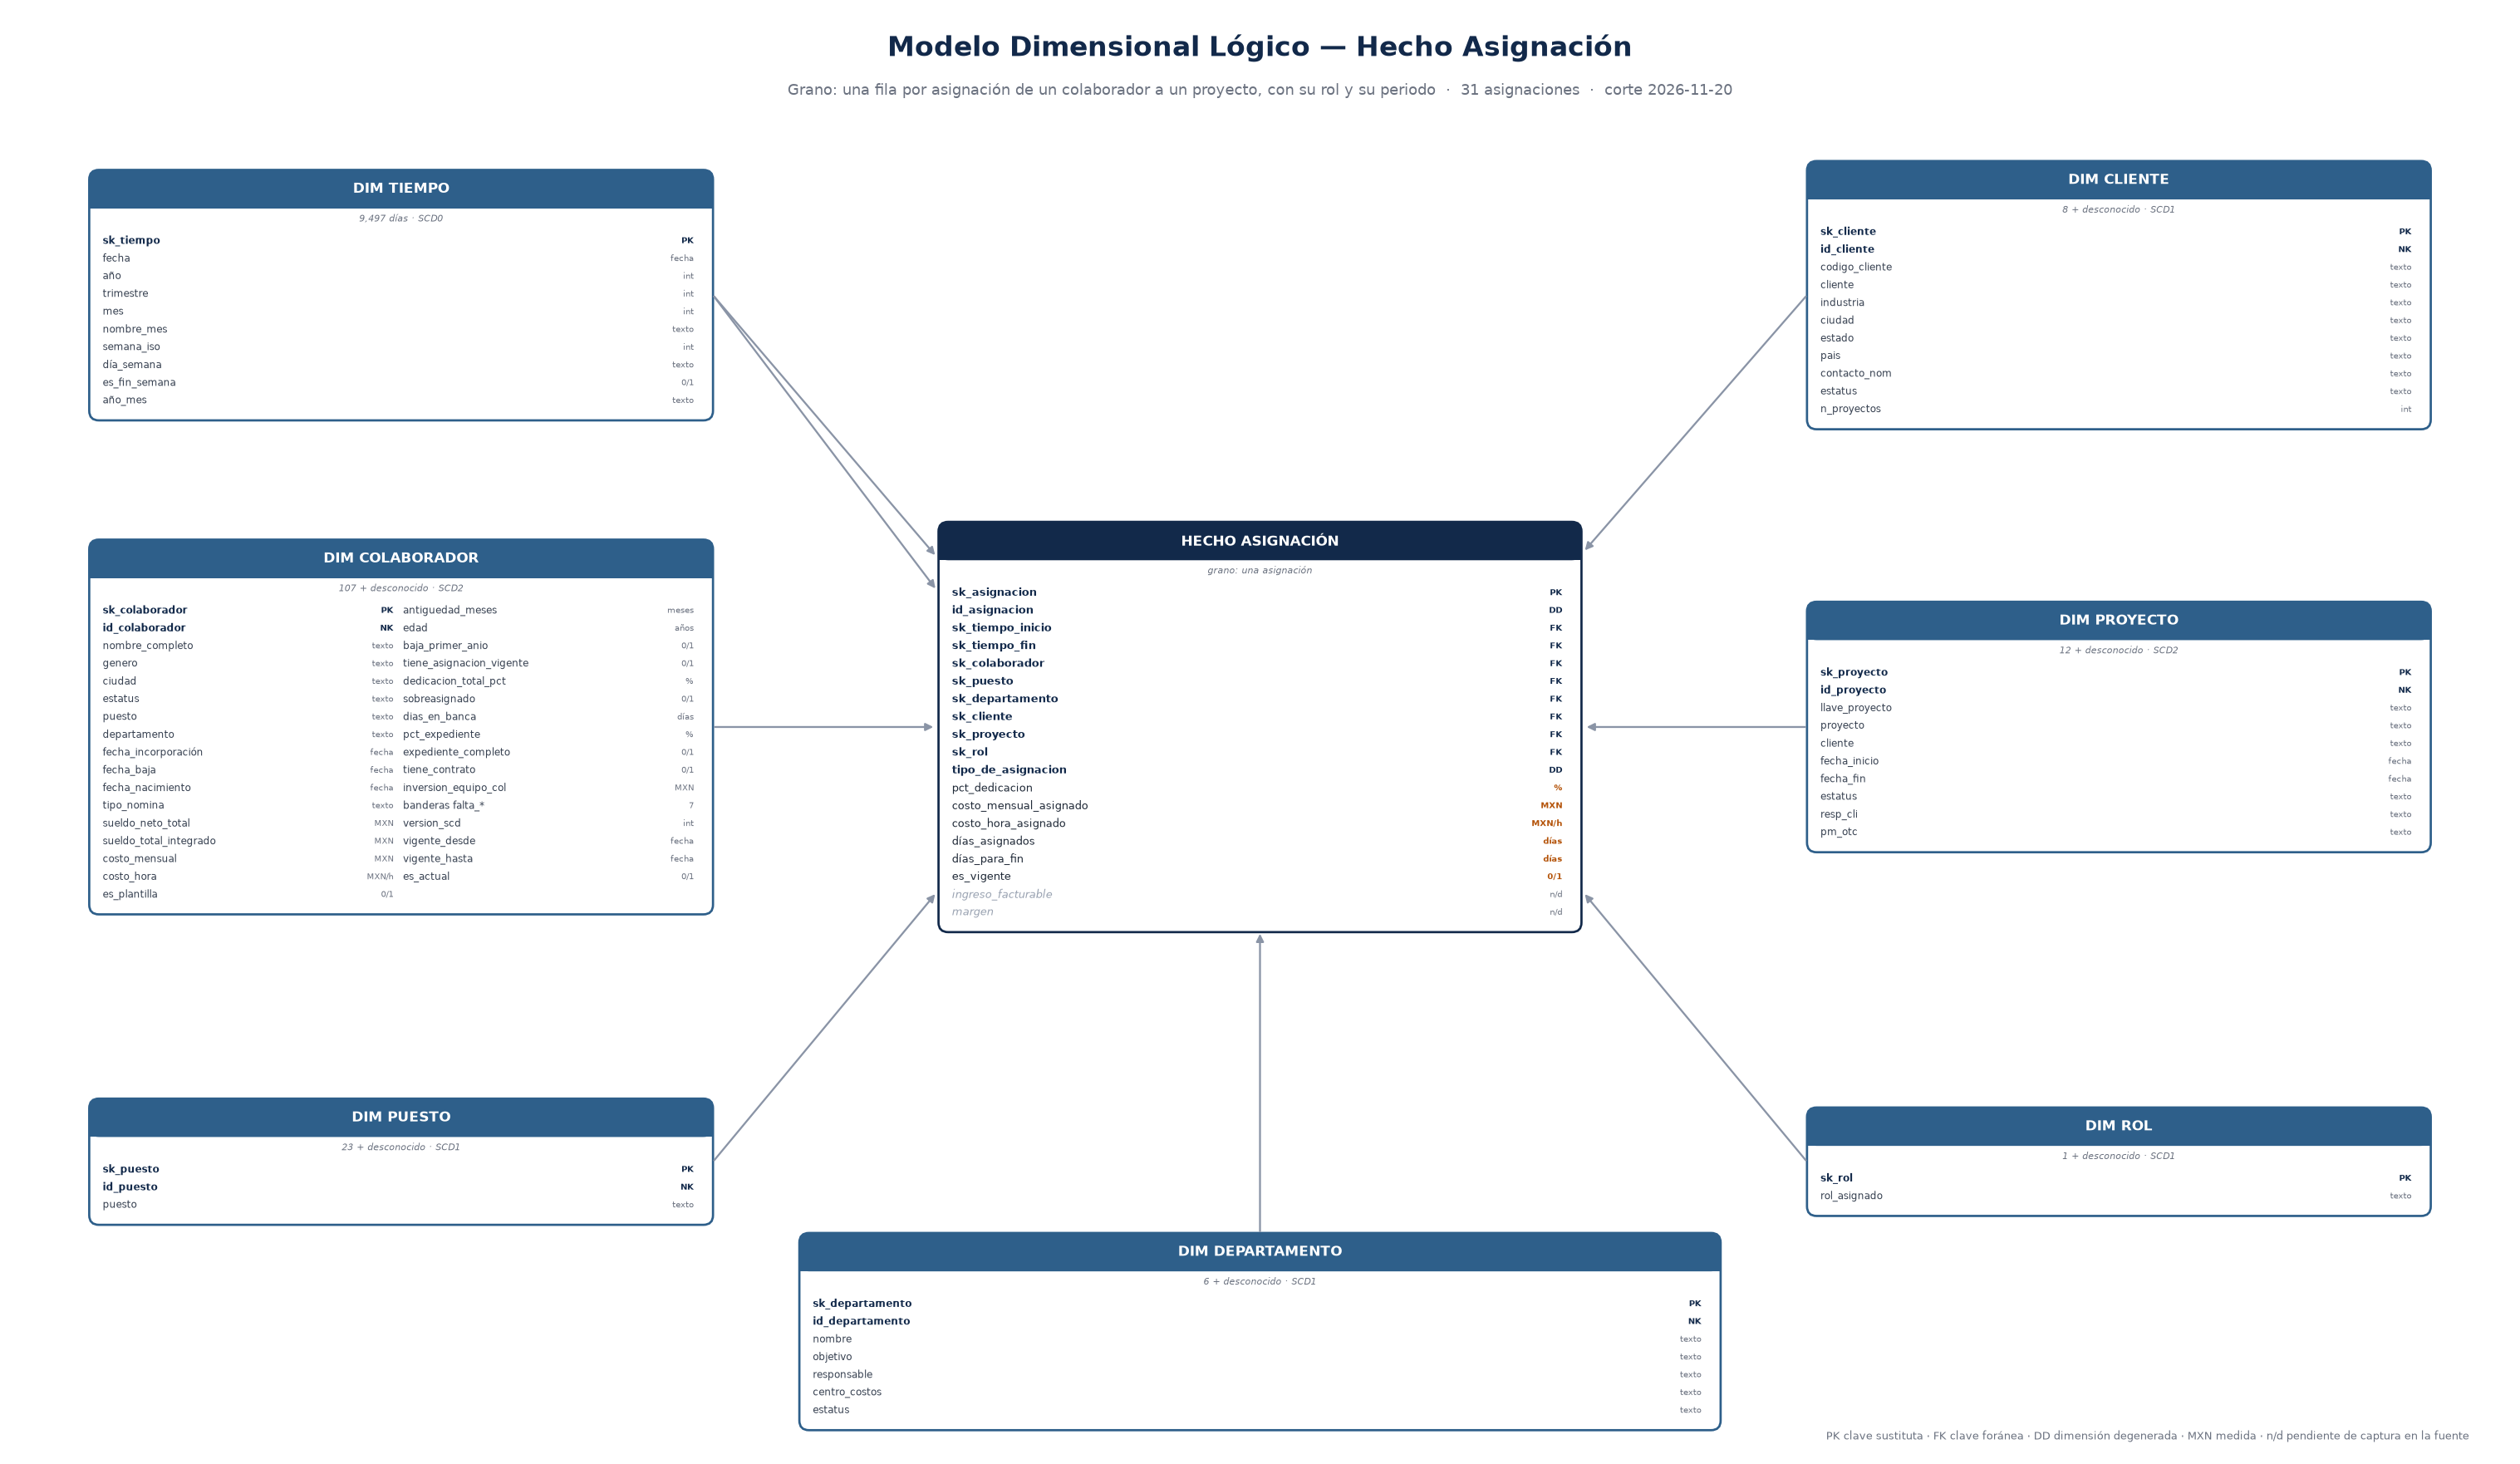

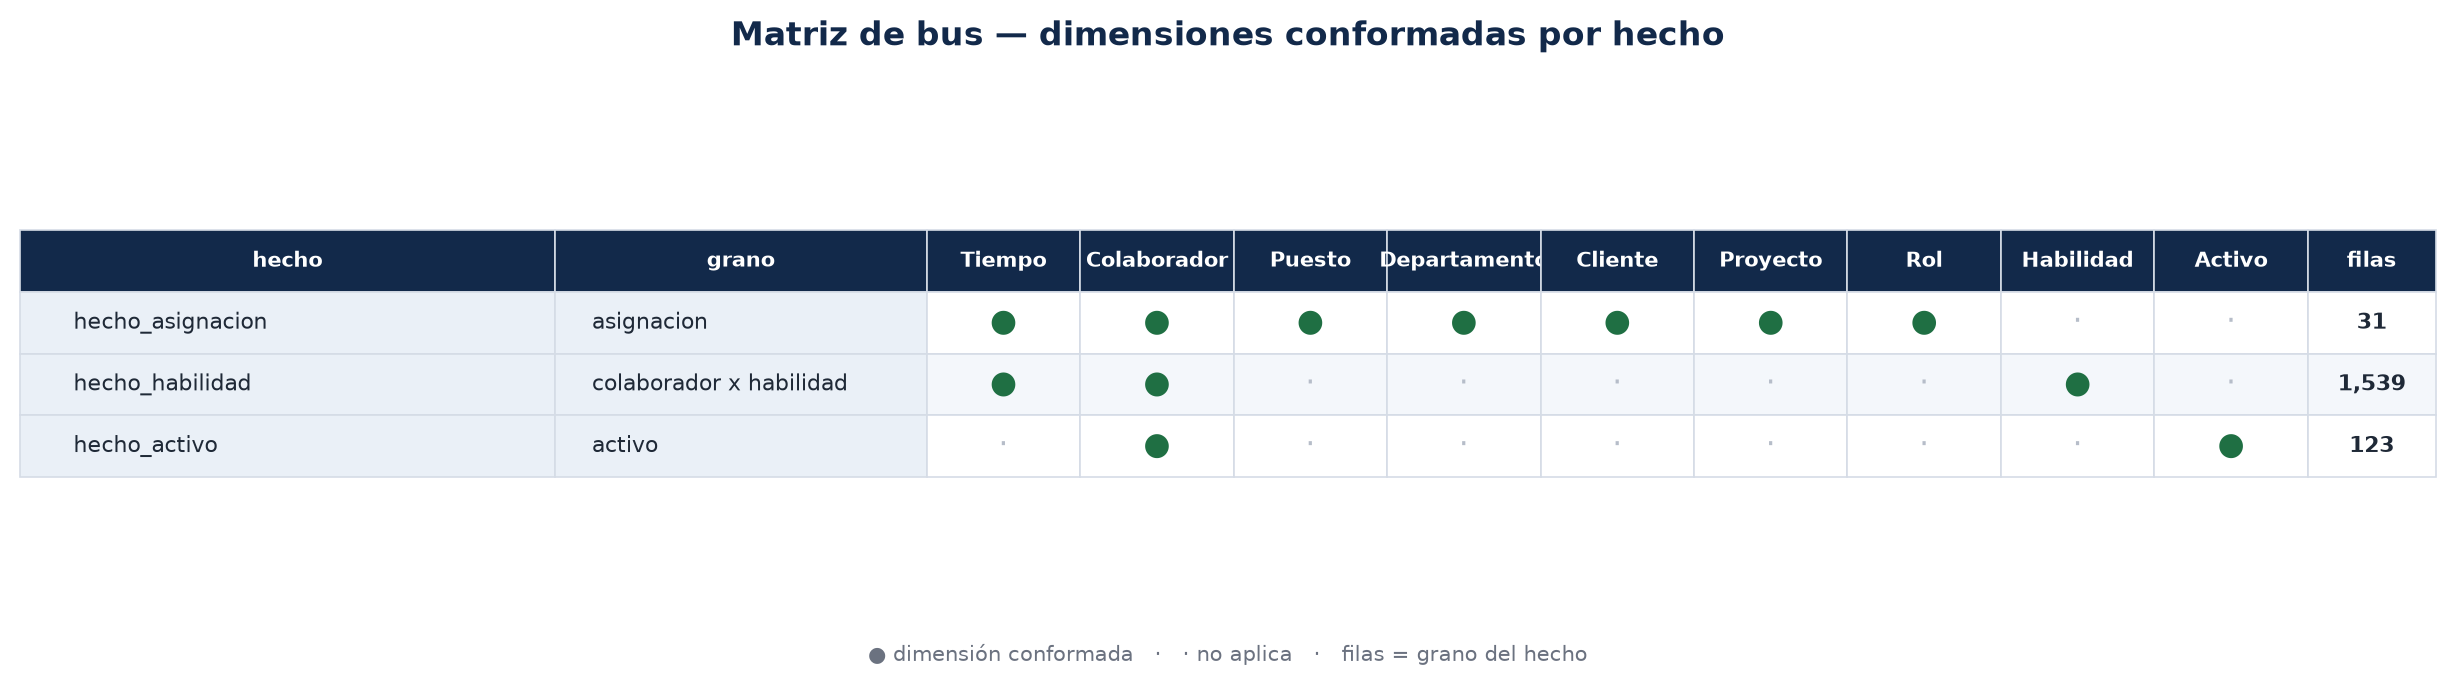

In [6]:
from IPython.display import Image, display

ruta_estrella = DOCS / 'modelo_dimensional_logico.png'
ruta_bus = DOCS / 'matriz_bus.png'

dibujar_estrella(ruta_estrella)
dibujar_matriz(ruta_bus)

display(Image(filename=str(ruta_estrella), width=1150))
display(Image(filename=str(ruta_bus), width=900))

## B.1 y B.2 — Tabla de hechos y llaves del modelo

La tabla de hechos se arma de verdad, no solo se describe: se asignan las claves sustitutas, se resuelven las llaves foráneas y se cuentan los casos que caen en el miembro desconocido.

In [7]:
def mapa(serie):
    valores = sorted(pd.Series(serie).dropna().unique())
    return {valor: i + 1 for i, valor in enumerate(valores)}

mapa_colaborador = mapa(c.id_colaborador)
mapa_puesto = mapa(c.id_puesto.dropna().astype(int))
mapa_departamento = {nombre.casefold(): i + 1 for i, nombre in enumerate(sorted(datos['departamento_acondicionado'].nombre))}
mapa_cliente = mapa(datos['cliente_acondicionado'].id_cliente)
mapa_proyecto = mapa(datos['proyecto_acondicionado'].id_proyecto)
mapa_rol = mapa(a.rol_asignado)

persona = c.set_index('id_colaborador')

hecho = pd.DataFrame({
    'sk_asignacion': range(1, len(a) + 1),
    'id_asignacion': a.id_asignacion.values,
    'sk_tiempo_inicio': pd.to_datetime(a.fecha_inicio, errors='coerce').dt.strftime('%Y%m%d').fillna('0').astype(int),
    'sk_tiempo_fin': pd.to_datetime(a.fecha_fin, errors='coerce').dt.strftime('%Y%m%d').fillna('0').astype(int),
    'sk_colaborador': a.id_colaborador.map(mapa_colaborador),
    'sk_puesto': a.id_colaborador.map(persona.id_puesto).map(lambda v: mapa_puesto.get(int(v), 0) if pd.notna(v) else 0),
    'sk_departamento': a.id_colaborador.map(persona.departamento).map(lambda v: mapa_departamento.get(v.casefold(), 0) if isinstance(v, str) else 0),
    'sk_cliente': a.id_cliente.map(mapa_cliente),
    'sk_proyecto': a.id_proyecto.map(mapa_proyecto),
    'sk_rol': a.rol_asignado.map(lambda v: mapa_rol.get(v, 0)),
    'tipo_de_asignacion': a.tipo_de_asignacion,
    'pct_dedicacion': a.pct_dedicacion,
    'costo_mensual_asignado': a.costo_mensual_asignado.round(2),
    'costo_hora_asignado': a.costo_hora_asignado.round(2),
    'dias_asignados': a.dias_asignados,
    'dias_para_fin': a.dias_para_fin,
    'es_vigente': a.vigente.astype(int),
    'ingreso_facturable': pd.NA,
    'margen': pd.NA,
})

print(f'hecho_asignacion: {len(hecho)} filas x {len(hecho.columns)} columnas')
print(f'  costo mensual asignado: ${hecho.costo_mensual_asignado.sum():,.2f}')
print('  filas con llave desconocida: ' + ', '.join(
    f'{col} = {int((hecho[col] == 0).sum())}' for col in ['sk_puesto', 'sk_departamento', 'sk_rol']))
print(f'  días asignados nulos: {int(hecho.dias_asignados.isna().sum())}')
print()
print('  reparto ejemplo:')
print(hecho[['id_asignacion', 'sk_colaborador', 'sk_proyecto', 'sk_cliente', 'sk_tiempo_inicio', 'costo_mensual_asignado']].head(3).to_string(index=False))

print()
print(f'hecho_habilidad: {len(m):,} filas; {int(m.id_colaborador.isna().sum())} sin colaborador (sk = 0)')
print(f'hecho_activo: {len(activos):,} filas; {int(activos.id_colaborador.isna().sum())} sin resguardo (sk = 0)')

hecho_asignacion: 31 filas x 19 columnas
  costo mensual asignado: $2,025,644.02
  filas con llave desconocida: sk_puesto = 14, sk_departamento = 25, sk_rol = 29
  días asignados nulos: 21

  reparto ejemplo:
 id_asignacion  sk_colaborador  sk_proyecto  sk_cliente  sk_tiempo_inicio  costo_mensual_asignado
             1               2            3           5                 0                59397.28
             2               3            3           5                 0                67069.18
             3               4            2           5          20251103                65513.35

hecho_habilidad: 1,539 filas; 10 sin colaborador (sk = 0)
hecho_activo: 123 filas; 32 sin resguardo (sk = 0)


## Conclusiones del diseño

- El modelo tiene **tres hechos y nueve dimensiones**, con Tiempo y Colaborador conformadas, porque el reto mide tres procesos distintos y no uno.
- El grano de la asignación se validó contra los datos: **31 filas únicas, 0 duplicados y 0 huérfanos**.
- La tabla de hechos se puede construir hoy: el costo asignado suma **$2,025,644.02** y todas las asignaciones tienen costo.
- Los huecos de la fuente se representan, no se esconden: **29 asignaciones sin rol**, **21 sin fecha de inicio real**, **10 evaluaciones sin colaborador** y **32 activos sin resguardo** caen en el miembro desconocido.
- Cuatro medidas quedan nulas por falta de captura en la fuente: ingreso facturable, margen, brecha de nivel y vigencia de la matriz. El diseño las deja listas para cuando el socio capture tarifas, horas y fechas de evaluación.

El detalle completo, con la definición de cada columna y la justificación de cada decisión, está en `docs/ETAPA_4.md`.